Hard for trees dataset subset

In [8]:
import multiprocessing
multiprocessing.set_start_method("spawn", force=True)

import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold

# Project root
PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [9]:
import sys
from pathlib import Path

# Find project root automatically
PROJECT_ROOT = Path.cwd().parents[1]

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


In [10]:
from core.metrics import evaluate_tree_new
from evolution.encode_decode import decode
from evolution.genetic_DT_GA import evolve_trees, _load_dataset_csv

In [11]:
def eval_gene_on_dataset(gene, X, y, k=5, seed=123):

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)

    scores = []

    for tr, te in skf.split(X, y):

        algo = decode(gene)
        algo.fit(X[tr], y[tr])

        m = evaluate_tree_new(algo, X[te], y[te])
        scores.append(m["f1"])

    return np.array(scores)

Easy for trees:
Banknote
Iris
Car
TicTacToe
Anneal

Hard for trees:
Balance Scale
Arrhythmia
Heart Disease
Wine Red
Haberman

Interesting intermediate challenging:
Semeion
Sonar
Glass
Cylinder Bands

In [12]:
random.seed(42)

data_path = PROJECT_ROOT / "data"

# (5)
datasets = {
    "arrhythmia": data_path / "arrhythmia.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "haberman": data_path / "haberman.csv",
    "wine_red": data_path / "winequality_red.csv",
}

# (5)
unseen_datasets = {
    "iris": data_path / "iris.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
    "anneal": data_path / "anneal.csv"
}

target_cols = {name: None for name in list(datasets.keys()) + list(unseen_datasets.keys())}

In [13]:
mu = 25
lambd = 25
generations = 30

print("Starting Evolutionary Process...")
print(f"Experiment with mu={mu}, lambda={lambd} for {generations} generations.")
print("Training datasets:", list(datasets.keys()))

Starting Evolutionary Process...
Experiment with mu=25, lambda=25 for 30 generations.
Training datasets: ['arrhythmia', 'balance_scale', 'heart_disease', 'haberman', 'wine_red']


In [7]:
timestamp = time.strftime("%Y%m%d_%H%M")

results_dir = Path(
    r"C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs"
)

results_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved in:", results_dir)

Figures will be saved in: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs


In [8]:
evo_t0 = time.time()

best_gene, best_fit, history, fitness_rank_history, generalization_history, generalization_sdd_history = evolve_trees(
    datasets,
    unseen_datasets,
    target_cols=target_cols,
    mu=mu,
    lambd=lambd,
    generations=generations)

evo_tf = time.time()


# Tiempo total
total_time = evo_tf - evo_t0
total_minutes = total_time / 60
total_hours = total_time / 3600

# Tiempo promedio por generación
time_per_gen = total_time / generations

print("\n ===== Evolution Summary =====")
print(f"Total time: {total_time:.2f} seconds")
print(f"Total time: {total_minutes:.2f} minutes")
print(f"Total time: {total_hours:.2f} hours")
print(f"Avg time per generation: {time_per_gen:.2f} seconds")

print("\n ===== Results =====")
print("Best gene:", best_gene)
print("Fitness (mean - SDD):", best_fit)


[Evaluation] 25 genes | 5 datasets | 5 folds | workers=18 | timeout=900s

[Progress] 1/25 [OK] gene=[6, 4, 20, 2, 1, 0, 4, 10] fitness=0.0257 mean_f1=0.1609 f1_std=0.1353 total=75.68s pid=31088
  dataset mean F1 | best=0.4237 worst=0.0541 avg=0.1609
  dataset mean F1 values=[0.0541, 0.0667, 0.1405, 0.4237, 0.1197]
  - arrhythmia           F1 mean=0.0541 best=0.0542 worst=0.0539 folds=[0.0539, 0.0542]
    time total=2.17s decode=0.00s fit=2.09s metrics=0.03s | depth=0.00 nodes=1.00
  - balance_scale        F1 mean=0.0667 best=0.0667 worst=0.0667 folds=[0.0667, 0.0667, 0.0667, 0.0667, 0.0667]
    time total=0.24s decode=0.00s fit=0.11s metrics=0.11s | depth=0.00 nodes=1.00
  - heart_disease        F1 mean=0.1405 best=0.1419 worst=0.1391 folds=[0.1404, 0.1404, 0.1404, 0.1419, 0.1391]
    time total=0.36s decode=0.00s fit=0.24s metrics=0.09s | depth=0.00 nodes=1.00
  - haberman             F1 mean=0.4237 best=0.4245 worst=0.4206 folds=[0.4206, 0.4245, 0.4245, 0.4245, 0.4245]
    time tota

In [9]:
# Report generalization across datasets
for name, dataset_path in datasets.items():
    target_col = None if target_cols is None else target_cols.get(name, None)

    X, y = _load_dataset_csv(dataset_path, target_col=target_col)
    scores = eval_gene_on_dataset(best_gene, X, y, k=5)

    print(f"{name}: mean F1={scores.mean():.4f}, std F1={scores.std():.4f}, folds={scores}")

c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


arrhythmia: mean F1=0.4094, std F1=0.0344, folds=[0.38087121 0.37311119 0.41888766 0.47003877 0.4043105 ]
balance_scale: mean F1=0.1894, std F1=0.0129, folds=[0.20978463 0.17232901 0.19453988 0.1794461  0.19076459]
heart_disease: mean F1=0.3258, std F1=0.0498, folds=[0.3037931  0.30452736 0.42242424 0.28021569 0.31826882]
haberman: mean F1=0.5743, std F1=0.0454, folds=[0.55424837 0.53402778 0.54590571 0.66073415 0.57638889]
wine_red: mean F1=0.2932, std F1=0.0205, folds=[0.28723767 0.33367067 0.2870133  0.28021442 0.27808351]


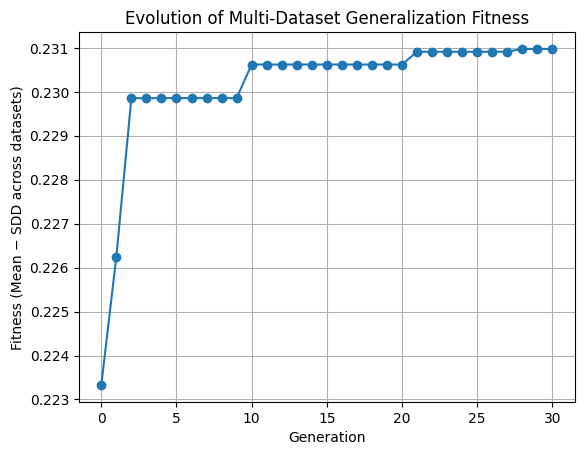

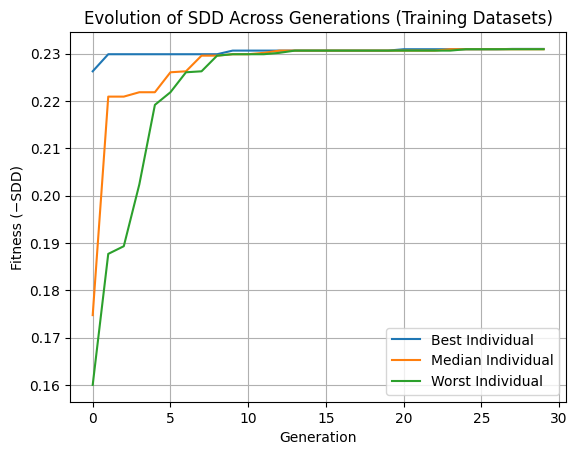

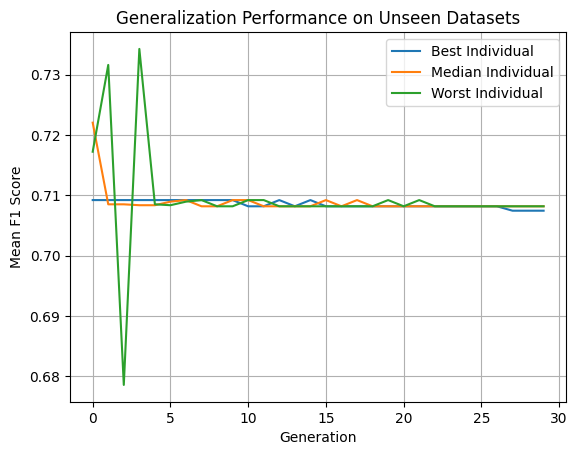

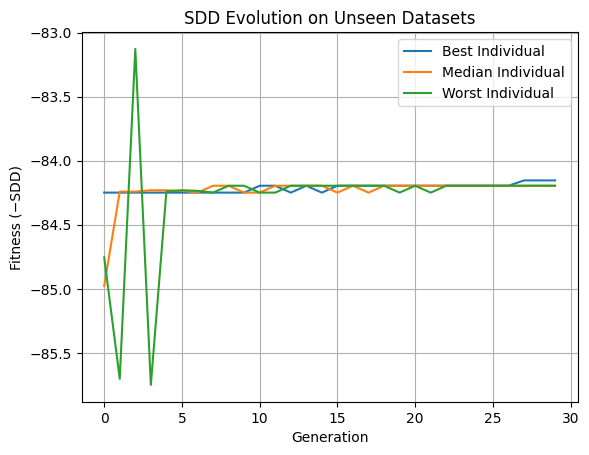

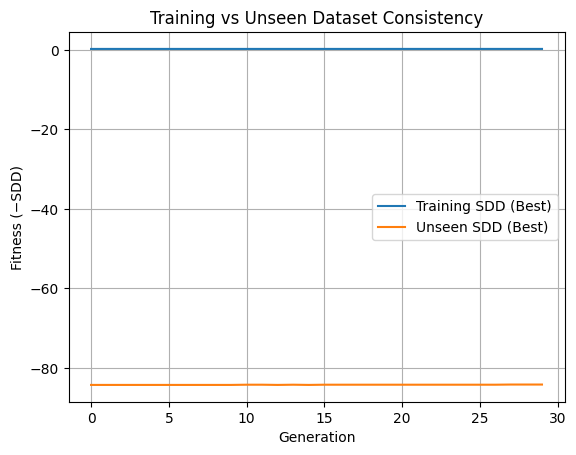

In [10]:
# Graph 1 — Best Fitness Evolution
fig = plt.figure()

plt.plot(history, marker="o")

plt.title("Evolution of Multi-Dataset Generalization Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD across datasets)")
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "fitness_evolution.png", dpi=300)



# Graph 2 — Training SDD Evolution
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Best Individual")
plt.plot(fitness_rank_history["median"], label="Median Individual")
plt.plot(fitness_rank_history["worst"], label="Worst Individual")

plt.title("Evolution of SDD Across Generations (Training Datasets)")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_sdd.png", dpi=300)



# Graph 3 — Generalization F1
fig = plt.figure()

plt.plot(generalization_history["best"], label="Best Individual")
plt.plot(generalization_history["median"], label="Median Individual")
plt.plot(generalization_history["worst"], label="Worst Individual")

plt.title("Generalization Performance on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Mean F1 Score")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "generalization_f1.png", dpi=300)



# Graph 4 — Unseen Dataset SDD
fig = plt.figure()

plt.plot(generalization_sdd_history["best"], label="Best Individual")
plt.plot(generalization_sdd_history["median"], label="Median Individual")
plt.plot(generalization_sdd_history["worst"], label="Worst Individual")

plt.title("SDD Evolution on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)

#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "unseen_sdd.png", dpi=300)



# Graph 5 — Training vs Unseen SDD
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Training SDD (Best)")
plt.plot(generalization_sdd_history["best"], label="Unseen SDD (Best)")

plt.title("Training vs Unseen Dataset Consistency")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_vs_unseen_sdd.png", dpi=300)

plt.show()

In [7]:
import numpy as np
import pandas as pd

from evolution.genetic_DT_GA import (
    _eval_one_algo_all_datasets,
    _fitness_from_dataset_scores,
)

def safe_xi(score, best=1.0, eps=1e-8):
    return abs(score - best) / (((score + best) / 2) + eps)

# ---- Put your winning genomes here ----
WINNING_GENES = {
    "mean_minus_sdd": [1, 1, 11, 1, 0, 0, 5, 3],
    "minus_sdd": [5, 4, 7, 1, 5, 1, 5, 1],
}

k_folds = 5
seed = 42
timeout_s = None

datasets_info = []
for ds_name, ds_path in datasets.items():
    target_col = None if "target_cols" not in globals() else target_cols.get(ds_name, None)
    datasets_info.append((ds_name, str(ds_path), target_col))

dataset_split_seeds = {
    ds_name: abs(hash((seed, ds_name))) % (2**31 - 1)
    for ds_name in datasets.keys()
}

summary_rows = []
detail_rows = []

for exp_name, gene in WINNING_GENES.items():
    print(f"\n===== FINAL EVALUATION: {exp_name} =====")
    print(f"Gene: {gene}")

    out = _eval_one_algo_all_datasets(
        algo_genome=gene,
        datasets_info=datasets_info,
        n_splits=k_folds,
        dataset_split_seeds=dataset_split_seeds,
        bad_score=0.0,
        timeout_s=timeout_s,
    )

    scores_by_dataset = out["results"]

    dataset_mean_f1 = {
        ds: float(np.mean(scores))
        for ds, scores in scores_by_dataset.items()
    }

    dataset_f1_scores = np.array(list(dataset_mean_f1.values()), dtype=float)

    mean_f1 = float(np.mean(dataset_f1_scores))

    # New SDD: percentage differences using best dataset F1 for this genome
    best_dataset_f1 = float(np.max(dataset_f1_scores))

    xi = np.abs(dataset_f1_scores - best_dataset_f1) / (
        (dataset_f1_scores + best_dataset_f1) / 2 + 1e-8
    )

    SDD = float(np.std(xi))
    raw_std_across_datasets = float(np.std(dataset_f1_scores))

    fitness_mean_minus_sdd = mean_f1 - SDD
    fitness_minus_sdd = -SDD

    # Old SDD from the previous -SDD experiment:
    # xi_i = relative difference between dataset mean F1 and ideal best = 1.0
    old_xi_values = np.array([safe_xi(score, best=1.0) for score in dataset_f1_scores], dtype=float)

    if len(old_xi_values) <= 1:
        old_xi_sdd = 0.0
    else:
        old_xi_sdd = float(np.std(old_xi_values, ddof=1))

    old_fitness_minus_sdd = -old_xi_sdd

    print(f"Mean F1: {mean_f1:.6f}")
    print(f"New SDD across datasets: {SDD:.6f}")
    print(f"New Fitness mean - SDD: {fitness_mean_minus_sdd:.6f}")
    print(f"New Fitness -SDD: {fitness_minus_sdd:.6f}")
    print(f"Raw std F1 across datasets: {raw_std_across_datasets:.6f}")
    print(f"Old xi-based SDD: {old_xi_sdd:.6f}")
    print(f"Old Fitness -SDD: {old_fitness_minus_sdd:.6f}")

    summary_rows.append({
        "experiment": exp_name,
        "gene": gene,
        "mean_f1": mean_f1,

        "new_SDD": SDD,
        "new_fitness_mean_minus_SDD": fitness_mean_minus_sdd,
        "new_fitness_minus_SDD": fitness_minus_sdd,

        "raw_std_f1_across_datasets": raw_std_across_datasets,

        "old_xi_based_SDD": old_xi_sdd,
        "old_fitness_minus_SDD": old_fitness_minus_sdd,
        "old_xi_values": old_xi_values.tolist(),

        "infeasible": out["infeasible"],
        "failed_dataset": out["failed_dataset"],
        "failure_reason": out["failure_reason"],
    })

    for ds, scores in scores_by_dataset.items():
        times = out["times"][ds]
        struct = out["structures"][ds]

        mean_ds_f1 = float(np.mean(scores))
        old_ds_xi = safe_xi(mean_ds_f1, best=1.0)

        detail_rows.append({
            "experiment": exp_name,
            "dataset": ds,
            "mean_f1": mean_ds_f1,
            "std_f1_folds": float(np.std(scores)),
            "best_fold_f1": float(np.max(scores)),
            "worst_fold_f1": float(np.min(scores)),
            "old_xi_distance_from_1": old_ds_xi,
            "fold_scores": scores,
            "total_time_s": times["total"],
            "fit_time_s": times["fit"],
            "mean_depth": struct["depth"],
            "mean_nodes": struct["nodes"],
        })

summary_df = pd.DataFrame(summary_rows)
details_df = pd.DataFrame(detail_rows)

display(summary_df)
display(details_df.sort_values(["experiment", "mean_f1"], ascending=[True, False]))


===== FINAL EVALUATION: mean_minus_sdd =====
Gene: [1, 1, 11, 1, 0, 0, 5, 3]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1: 0.319546
New SDD across datasets: 0.299276
New Fitness mean - SDD: 0.020271
New Fitness -SDD: -0.299276
Raw std F1 across datasets: 0.113572
Old xi-based SDD: 0.269846
Old Fitness -SDD: -0.269846

===== FINAL EVALUATION: minus_sdd =====
Gene: [5, 4, 7, 1, 5, 1, 5, 1]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1: 0.279566
New SDD across datasets: 0.273942
New Fitness mean - SDD: 0.005624
New Fitness -SDD: -0.273942
Raw std F1 across datasets: 0.083357
Old xi-based SDD: 0.220763
Old Fitness -SDD: -0.220763


,experiment,gene,mean_f1,new_SDD,new_fitness_mean_minus_SDD,new_fitness_minus_SDD,raw_std_f1_across_datasets,old_xi_based_SDD,old_fitness_minus_SDD,old_xi_values,infeasible,failed_dataset,failure_reason
0,mean_minus_sdd,"[1, 1, 11, 1, 0, 0, 5, 3]",0.319546,0.299276,0.020271,-0.299276,0.113572,0.269846,-0.269846,"[1.0409520505832168, 1.3275983403257523, 1.153...",False,None,None
1,minus_sdd,"[5, 4, 7, 1, 5, 1, 5, 1]",0.279566,0.273942,0.005624,-0.273942,0.083357,0.220763,-0.220763,"[1.289716359572378, 1.3837923019233211, 1.1334...",False,None,None


,experiment,dataset,mean_f1,std_f1_folds,best_fold_f1,worst_fold_f1,old_xi_distance_from_1,fold_scores,total_time_s,fit_time_s,mean_depth,mean_nodes
3,mean_minus_sdd,haberman,0.534642,0.058447,0.598155,0.439224,0.606472,"[0.5502100038182512, 0.5981554677206851, 0.500...",4.285173,4.243455,13.0,359.8
0,mean_minus_sdd,arrhythmia,0.315378,0.023898,0.339276,0.291479,1.040952,"[0.29147928686713886, 0.339275761318385]",97.063083,97.028654,13.0,207.0
4,mean_minus_sdd,wine_red,0.277396,0.020397,0.309105,0.244824,1.131371,"[0.275067647745824, 0.2802711207939966, 0.2448...",33.830531,33.767502,13.0,1183.8
2,mean_minus_sdd,heart_disease,0.268248,0.032266,0.324306,0.236991,1.153957,"[0.28345840778241016, 0.32430641821946166, 0.2...",13.420081,13.387787,13.0,434.2
1,mean_minus_sdd,balance_scale,0.202068,0.031202,0.260284,0.173214,1.327598,"[0.19068734347209923, 0.17321426077240032, 0.2...",15.937869,15.897840,13.0,1052.6
8,minus_sdd,haberman,0.423735,0.001587,0.424528,0.420561,0.809512,"[0.4205607476635514, 0.42452830188679247, 0.42...",0.030687,0.003816,0.0,1.0
9,minus_sdd,wine_red,0.299517,0.014340,0.321006,0.280897,1.078068,"[0.3063044388183624, 0.32100580973129994, 0.28...",157.964506,157.905426,25.0,1954.6
7,minus_sdd,heart_disease,0.276561,0.035500,0.322251,0.224744,1.133417,"[0.3222510822510822, 0.30401563610518834, 0.28...",77.701758,77.660292,25.0,568.6
5,minus_sdd,arrhythmia,0.215910,0.025068,0.240978,0.190843,1.289716,"[0.24097786271699315, 0.19084271814647244]",154.905555,154.872800,25.0,155.0
6,minus_sdd,balance_scale,0.182106,0.041534,0.255313,0.140087,1.383792,"[0.14573416734891065, 0.140087117851093, 0.193...",202.101156,202.052467,25.0,4469.8


In [14]:
import numpy as np
import pandas as pd

from evolution.genetic_DT_GA import _eval_one_algo_all_datasets


# ---- Winning genomes ----
WINNING_GENES = {
    "mean_minus_sdd": [1, 1, 11, 1, 0, 0, 5, 3],
    "minus_sdd": [5, 4, 7, 1, 5, 1, 5, 1],
}

k_folds = 5
seed = 42
timeout_s = None


def compute_clean_metrics(scores_by_dataset):
    """
    Computes final report metrics:
    1. Mean F1 across datasets
    2. SDD across datasets, using the old xi-based definition
    3. Raw standard deviation of dataset mean F1
    4. Fitness = Mean(F1) - SDD, where SDD is raw std of F1
       exactly like _fitness_from_dataset_scores
    """

    dataset_mean_f1_values = []

    for scores in scores_by_dataset.values():
        clean_scores = [float(s) for s in scores if np.isfinite(s)]
        mean_f1 = float(np.mean(clean_scores)) if clean_scores else 0.0
        dataset_mean_f1_values.append(mean_f1)

    dataset_mean_f1_values = np.array(dataset_mean_f1_values, dtype=float)

    if len(dataset_mean_f1_values) == 0:
        return -np.inf, np.inf, np.inf, -np.inf, []

    # 1. Mean F1 across datasets
    mean_f1 = float(np.mean(dataset_mean_f1_values))

    # 2. SDD across datasets: old xi-based SDD
    xi_values = np.abs(dataset_mean_f1_values - 1.0) / (
        ((dataset_mean_f1_values + 1.0) / 2) + 1e-8
    )

    sdd_across_datasets = (
        float(np.std(xi_values, ddof=1))
        if len(xi_values) > 1
        else 0.0
    )

    old_fitness_minus_sdd = -sdd_across_datasets

    # 3. Raw standard deviation of F1
    raw_std_f1 = float(np.std(dataset_mean_f1_values))

    # 4. Fitness exactly as in your current function:
    # Mean(F1) - std(dataset_mean_f1_values)
    fitness_mean_f1_minus_std = mean_f1 - raw_std_f1

    return (
        mean_f1,
        old_fitness_minus_sdd,
        raw_std_f1,
        fitness_mean_f1_minus_std,
        dataset_mean_f1_values.tolist(),
    )


datasets_info = []
for ds_name, ds_path in datasets.items():
    target_col = None if "target_cols" not in globals() else target_cols.get(ds_name, None)
    datasets_info.append((ds_name, str(ds_path), target_col))


dataset_split_seeds = {
    ds_name: abs(hash((seed, ds_name))) % (2**31 - 1)
    for ds_name in datasets.keys()
}


summary_rows = []
detail_rows = []


for exp_name, gene in WINNING_GENES.items():
    print(f"\n===== FINAL EVALUATION: {exp_name} =====")
    print(f"Gene: {gene}")

    out = _eval_one_algo_all_datasets(
        algo_genome=gene,
        datasets_info=datasets_info,
        n_splits=k_folds,
        dataset_split_seeds=dataset_split_seeds,
        bad_score=0.0,
        timeout_s=timeout_s,
    )

    scores_by_dataset = out["results"]

    (
        mean_f1,
        old_fitness_minus_sdd,
        raw_std_f1,
        fitness_mean_f1_minus_sdd,
        dataset_mean_f1_values,
    ) = compute_clean_metrics(scores_by_dataset)

    print(f"Mean F1 across datasets: {mean_f1:.6f}")
    print(f"SDD across datasets / Old Fitness -SDD: {old_fitness_minus_sdd:.6f}")
    print(f"Raw standard deviation of F1: {raw_std_f1:.6f}")
    print(f"Fitness Mean(F1) - SDD: {fitness_mean_f1_minus_sdd:.6f}")

    summary_rows.append({
        "experiment": exp_name,
        "gene": gene,
        "mean_f1_across_datasets": mean_f1,
        "old_fitness_minus_sdd": old_fitness_minus_sdd,
        "raw_std_f1_across_datasets": raw_std_f1,
        "fitness_mean_f1_minus_sdd": fitness_mean_f1_minus_sdd,
        "dataset_mean_f1_values": dataset_mean_f1_values,
        "infeasible": out["infeasible"],
        "failed_dataset": out["failed_dataset"],
        "failure_reason": out["failure_reason"],
    })

    for ds, scores in scores_by_dataset.items():
        clean_scores = [float(s) for s in scores if np.isfinite(s)]

        detail_rows.append({
            "experiment": exp_name,
            "dataset": ds,
            "mean_f1": float(np.mean(clean_scores)) if clean_scores else 0.0,
            "std_f1_folds": float(np.std(clean_scores)) if clean_scores else 0.0,
            "fold_scores": clean_scores,
        })


summary_df = pd.DataFrame(summary_rows)
details_df = pd.DataFrame(detail_rows)

display(summary_df)
display(details_df.sort_values(
    ["experiment", "mean_f1"],
    ascending=[True, False]
))


===== FINAL EVALUATION: mean_minus_sdd =====
Gene: [1, 1, 11, 1, 0, 0, 5, 3]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1 across datasets: 0.319546
SDD across datasets / Old Fitness -SDD: -0.269846
Raw standard deviation of F1: 0.113572
Fitness Mean(F1) - SDD: 0.205974

===== FINAL EVALUATION: minus_sdd =====
Gene: [5, 4, 7, 1, 5, 1, 5, 1]
[CV warning] arrhythmia: requested 5 folds, using 2 because the rarest class has too few samples.
Mean F1 across datasets: 0.279566
SDD across datasets / Old Fitness -SDD: -0.220763
Raw standard deviation of F1: 0.083357
Fitness Mean(F1) - SDD: 0.196208


,experiment,gene,mean_f1_across_datasets,old_fitness_minus_sdd,raw_std_f1_across_datasets,fitness_mean_f1_minus_sdd,dataset_mean_f1_values,infeasible,failed_dataset,failure_reason
0,mean_minus_sdd,"[1, 1, 11, 1, 0, 0, 5, 3]",0.319546,-0.269846,0.113572,0.205974,"[0.31537752409276193, 0.2020681477610235, 0.26...",False,None,None
1,minus_sdd,"[5, 4, 7, 1, 5, 1, 5, 1]",0.279566,-0.220763,0.083357,0.196208,"[0.2159102904317328, 0.18210564225546144, 0.27...",False,None,None


,experiment,dataset,mean_f1,std_f1_folds,fold_scores
3,mean_minus_sdd,haberman,0.534642,0.058447,"[0.5502100038182512, 0.5981554677206851, 0.500..."
0,mean_minus_sdd,arrhythmia,0.315378,0.023898,"[0.29147928686713886, 0.339275761318385]"
4,mean_minus_sdd,wine_red,0.277396,0.020397,"[0.275067647745824, 0.2802711207939966, 0.2448..."
2,mean_minus_sdd,heart_disease,0.268248,0.032266,"[0.28345840778241016, 0.32430641821946166, 0.2..."
1,mean_minus_sdd,balance_scale,0.202068,0.031202,"[0.19068734347209923, 0.17321426077240032, 0.2..."
8,minus_sdd,haberman,0.423735,0.001587,"[0.4205607476635514, 0.42452830188679247, 0.42..."
9,minus_sdd,wine_red,0.299517,0.014340,"[0.3063044388183624, 0.32100580973129994, 0.28..."
7,minus_sdd,heart_disease,0.276561,0.035500,"[0.3222510822510822, 0.30401563610518834, 0.28..."
5,minus_sdd,arrhythmia,0.215910,0.025068,"[0.24097786271699315, 0.19084271814647244]"
6,minus_sdd,balance_scale,0.182106,0.041534,"[0.14573416734891065, 0.140087117851093, 0.193..."
